In [1]:

from pathlib import Path
from collections import Counter
import csv
import random
import numpy as np
import torch
import timm

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Project paths
DATA_DIR = Path.cwd()
SPLIT_FILE = DATA_DIR / "dataset_split.csv"

MODEL_NAME = "tiny_vit_21m_224.in1k"

RESULTS_DIR = DATA_DIR / "results" / "tinyvit_21m"
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# 3. Device
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# 4. Verify saved dataset split
assert SPLIT_FILE.exists(), "dataset_split.csv not found"

with open(SPLIT_FILE, "r", encoding="utf-8-sig") as f:
    split_records = list(csv.DictReader(f))

split_counts = Counter(
    row["split"] for row in split_records
)

assert split_counts == {
    "train": 1402,
    "validation": 280,
    "test": 279
}

# 5. Verify model availability
available_models = timm.list_models(
    "*tiny_vit_21m*",
    pretrained=True,
    include_tags=True
)

print("AVAILABLE TINYVIT-21M MODELS")
for name in available_models:
    print(" -", name)

assert MODEL_NAME in available_models

# 6. Load ImageNet-1K pretrained TinyViT-21M
model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=3
)

model = model.to(DEVICE)
model.eval()

# 7. Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

resnet50_reference = 25_557_032

difference_pct = (
    total_params / resnet50_reference - 1
) * 100

# 8. Inspect architecture
print("\nMODEL INFORMATION")
print("-" * 55)

print("Architecture:", MODEL_NAME)
print("Device:", DEVICE)
print("Total parameters:", f"{total_params:,}")

print("\nResNet-50 reference parameters:",
      f"{resnet50_reference:,}")

print(f"Parameter difference: {difference_pct:+.2f}%")

print("\nCLASSIFICATION HEAD")
print(model.get_classifier())

# 9. Inspect pretrained preprocessing
data_config = timm.data.resolve_model_data_config(model)

print("\nPRETRAINED DATA CONFIG")
for key in ["input_size", "mean", "std", "interpolation"]:
    print(f"{key}: {data_config.get(key)}")

# 10. Test forward pass
dummy_images = torch.randn(
    2, 3, 224, 224,
    device=DEVICE
)

with torch.inference_mode():
    outputs = model(dummy_images)

print("\nFORWARD PASS")
print("Input:", dummy_images.shape)
print("Output:", outputs.shape)

assert outputs.shape == (2, 3)

del dummy_images, outputs

# 11. Final verification
print("\nDATASET SPLIT")
print(dict(split_counts))

print("\nRESULTS DIRECTORY")
print(RESULTS_DIR)

print("\nTinyViT-21M setup successful!")


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


AVAILABLE TINYVIT-21M MODELS
 - tiny_vit_21m_224.dist_in22k
 - tiny_vit_21m_224.dist_in22k_ft_in1k
 - tiny_vit_21m_224.in1k
 - tiny_vit_21m_384.dist_in22k_ft_in1k
 - tiny_vit_21m_512.dist_in22k_ft_in1k



MODEL INFORMATION
-------------------------------------------------------
Architecture: tiny_vit_21m_224.in1k
Device: mps
Total parameters: 20,623,299

ResNet-50 reference parameters: 25,557,032
Parameter difference: -19.30%

CLASSIFICATION HEAD
Linear(in_features=576, out_features=3, bias=True)

PRETRAINED DATA CONFIG
input_size: (3, 224, 224)
mean: (0.485, 0.456, 0.406)
std: (0.229, 0.224, 0.225)
interpolation: bicubic

FORWARD PASS
Input: torch.Size([2, 3, 224, 224])
Output: torch.Size([2, 3])

DATASET SPLIT
{'train': 1402, 'validation': 280, 'test': 279}

RESULTS DIRECTORY
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m

TinyViT-21M setup successful!


In [2]:

# 1. Inspect top-level architecture
print("TINYVIT-21M ARCHITECTURE")
print("=" * 55)

for name, module in model.named_children():

    params = sum(
        p.numel() for p in module.parameters()
    )

    print(
        f"{name:<20} | "
        f"{type(module).__name__:<25} | "
        f"{params:,} parameters"
    )

# 2. Inspect individual stages
print("\nTINYVIT STAGES")
print("-" * 55)

for i, stage in enumerate(model.stages):

    params = sum(
        p.numel() for p in stage.parameters()
    )

    print(
        f"Stage {i+1}: "
        f"{type(stage).__name__} | "
        f"{params:,} parameters"
    )

# 3. Inspect classification head
print("\nCLASSIFICATION HEAD")
print("-" * 55)

print("Module name: head.fc")
print("Structure:", model.head.fc)

# 4. Freeze every parameter
for param in model.parameters():
    param.requires_grad = False

# 5. Unfreeze only final classification layer
for param in model.head.fc.parameters():
    param.requires_grad = True

# 6. Keep pretrained backbone in evaluation mode
model.eval()

# 7. Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

# 8. Verify trainable parameter names
trainable_layers = [
    (name, tuple(param.shape))
    for name, param in model.named_parameters()
    if param.requires_grad
]

expected_trainable = (
    model.head.fc.in_features * 3 + 3
)

assert model.head.fc.out_features == 3
assert trainable_params == expected_trainable
assert len(trainable_layers) == 2

# 9. Print configuration
print("\nHEAD-ONLY TRAINING CONFIGURATION")
print("-" * 55)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {frozen_params:,}")

print("\nTrainable layers:")

for name, shape in trainable_layers:
    print(f"  {name}: {shape}")

print("\nHead-only setup successful!")


TINYVIT-21M ARCHITECTURE
patch_embed          | PatchEmbed                | 43,056 parameters
stages               | Sequential                | 20,577,360 parameters
head                 | NormMlpClassifierHead     | 2,883 parameters

TINYVIT STAGES
-------------------------------------------------------
Stage 1: ConvLayer | 157,824 parameters
Stage 2: TinyVitStage | 952,716 parameters
Stage 3: TinyVitStage | 10,913,184 parameters
Stage 4: TinyVitStage | 8,553,636 parameters

CLASSIFICATION HEAD
-------------------------------------------------------
Module name: head.fc
Structure: Linear(in_features=576, out_features=3, bias=True)

HEAD-ONLY TRAINING CONFIGURATION
-------------------------------------------------------
Total parameters:     20,623,299
Trainable parameters: 1,731
Frozen parameters:    20,621,568

Trainable layers:
  head.fc.weight: (3, 576)
  head.fc.bias: (3,)

Head-only setup successful!


In [3]:

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# 1. Class mapping
CLASSES = ["Brittle", "Ductile", "Mixed"]

class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

# 2. Use the existing split manifest
train_records = [
    r for r in split_records
    if r["split"] == "train"
]

val_records = [
    r for r in split_records
    if r["split"] == "validation"
]

test_records = [
    r for r in split_records
    if r["split"] == "test"
]

# 3. Same ImageNet normalization
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 4. Training transforms
train_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 5. Validation transforms
eval_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 6. Dataset class
class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = data_dir
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):

        row = self.records[idx]

        image_path = (
            self.data_dir
            / row["label"]
            / row["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["label"]]

        return image, label

# 7. Create training and validation datasets
train_dataset = SEMDataset(
    train_records,
    DATA_DIR,
    train_transform
)

val_dataset = SEMDataset(
    val_records,
    DATA_DIR,
    eval_transform
)

# Test records remain reserved and unused.

# 8. DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# 9. Class distributions
train_counts = Counter(
    r["label"] for r in train_records
)

val_counts = Counter(
    r["label"] for r in val_records
)

test_counts = Counter(
    r["label"] for r in test_records
)

# 10. Verify group separation
train_groups = {r["group"] for r in train_records}
val_groups = {r["group"] for r in val_records}
test_groups = {r["group"] for r in test_records}

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# 11. Verify identical image counts
assert len(train_dataset) == 1402
assert len(val_dataset) == 280
assert len(test_records) == 279

# 12. Verify batch dimensions
images, labels = next(iter(train_loader))

assert images.shape == (16, 3, 224, 224)
assert labels.shape == (16,)

# 13. Print results
print("TINYVIT-21M DATASET VERIFICATION")
print("=" * 55)

print("\nDATASET SIZES")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Reserved test:", len(test_records))

print("\nCLASS DISTRIBUTION")
print(f"{'Class':<12} {'Train':>8} {'Val':>8} {'Test':>8}")

for cls in CLASSES:
    print(
        f"{cls:<12} "
        f"{train_counts[cls]:>8} "
        f"{val_counts[cls]:>8} "
        f"{test_counts[cls]:>8}"
    )

print("\nGROUP SEPARATION")
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Test groups:", len(test_groups))

print("\nBATCH VERIFICATION")
print("Images:", images.shape)
print("Labels:", labels.shape)

print("\nDataset setup successful!")


TINYVIT-21M DATASET VERIFICATION

DATASET SIZES
Training: 1402
Validation: 280
Reserved test: 279

CLASS DISTRIBUTION
Class           Train      Val     Test
Brittle           589      117      116
Ductile           711      142      143
Mixed             102       21       20

GROUP SEPARATION
Training groups: 147
Validation groups: 28
Test groups: 31

BATCH VERIFICATION
Images: torch.Size([16, 3, 224, 224])
Labels: torch.Size([16])

Dataset setup successful!


In [4]:

import torch.nn as nn

# 1. Calculate class weights from training data
num_samples = len(train_records)
num_classes = len(CLASSES)

class_weights = torch.tensor(
    [
        num_samples / (num_classes * train_counts[cls])
        for cls in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

# 2. Weighted cross-entropy
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# 3. Head-only optimizer
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    model.head.fc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# 4. Training settings
MAX_EPOCHS = 10

checkpoint_path = (
    CHECKPOINT_DIR / "tinyvit_21m_best.pth"
)

# 5. Verify optimizer contains only trainable head
optimized_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

assert optimized_params == trainable_params
assert trainable_params == 1731

# 6. Test forward and backward passes
# This diagnostic does not update the model.

model.eval()

optimizer.zero_grad(set_to_none=True)

images, labels = next(iter(train_loader))

images = images.to(DEVICE)
labels = labels.to(DEVICE)

outputs = model(images)

loss = criterion(outputs, labels)

loss.backward()

# 7. Verify classifier gradients
weight_grad = model.head.fc.weight.grad
bias_grad = model.head.fc.bias.grad

assert weight_grad is not None
assert bias_grad is not None

assert torch.isfinite(weight_grad).all().item()
assert torch.isfinite(bias_grad).all().item()

weight_grad_norm = weight_grad.norm().item()
bias_grad_norm = bias_grad.norm().item()

# Frozen backbone must have no gradients
frozen_grad_count = sum(
    p.grad is not None
    for name, p in model.named_parameters()
    if not name.startswith("head.fc.")
)

assert frozen_grad_count == 0

# Clear diagnostic gradients
optimizer.zero_grad(set_to_none=True)

# 8. Print verification
print("TINYVIT-21M HEAD-ONLY TRAINING CONFIGURATION")
print("=" * 60)

print("\nCLASS WEIGHTS")
for cls, weight in zip(CLASSES, class_weights):
    print(f"  {cls}: {weight.item():.4f}")

print("\nOPTIMIZER")
print("Type:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

print("\nPARAMETERS")
print(f"Total:     {total_params:,}")
print(f"Trainable: {trainable_params:,}")
print(f"Frozen:    {frozen_params:,}")

print("\nGRADIENT VERIFICATION")
print(f"Diagnostic loss: {loss.item():.4f}")
print(f"Head weight gradient norm: {weight_grad_norm:.6f}")
print(f"Head bias gradient norm:   {bias_grad_norm:.6f}")
print("Frozen parameters with gradients:", frozen_grad_count)

print("\nTRAINING PLAN")
print("Maximum epochs:", MAX_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Selection metric: Validation macro-F1")

print("\nCheckpoint destination:")
print(checkpoint_path)

print("\nConfiguration verified. Ready to train!")


TINYVIT-21M HEAD-ONLY TRAINING CONFIGURATION

CLASS WEIGHTS
  Brittle: 0.7934
  Ductile: 0.6573
  Mixed: 4.5817

OPTIMIZER
Type: AdamW
Learning rate: 0.001
Weight decay: 0.0001

PARAMETERS
Total:     20,623,299
Trainable: 1,731
Frozen:    20,621,568

GRADIENT VERIFICATION
Diagnostic loss: 1.2276
Head weight gradient norm: 6.243523
Head bias gradient norm:   0.193927
Frozen parameters with gradients: 0

TRAINING PLAN
Maximum epochs: 10
Batch size: 16
Selection metric: Validation macro-F1

Checkpoint destination:
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m/checkpoints/tinyvit_21m_best.pth

Configuration verified. Ready to train!


In [5]:

import time
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# 1. Initialize training history
history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_f1": [],
    "val_mixed_recall": [],
    "epoch_time": []
}

best_f1 = -1.0
best_epoch = 0

print("TRAINING TINYVIT-21M — HEAD ONLY")
print("=" * 85)

print("Architecture:", MODEL_NAME)
print("Device:", DEVICE)
print("Trainable parameters:", f"{trainable_params:,}")
print("Maximum epochs:", MAX_EPOCHS)
print("Selection metric: Validation macro-F1")
print()

# 2. Training loop
for epoch in range(MAX_EPOCHS):

    if DEVICE.type == "mps":
        torch.mps.synchronize()

    start_time = time.perf_counter()

    # Keep the pretrained backbone frozen
    # and its normalization statistics unchanged.
    # eval() does NOT disable gradient calculation.
    model.eval()

    total_train_loss = 0.0
    train_samples = 0

    # 3. Training batches
    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        total_train_loss += (
            loss.item() * batch_size
        )
        train_samples += batch_size

    train_loss = total_train_loss / train_samples

    # 4. Validation
    model.eval()

    total_val_loss = 0.0
    val_samples = 0

    all_labels = []
    all_predictions = []

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            total_val_loss += (
                loss.item() * batch_size
            )
            val_samples += batch_size

            predictions = outputs.argmax(dim=1)

            all_labels.extend(
                labels.cpu().tolist()
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

    val_loss = total_val_loss / val_samples

    # 5. Calculate validation metrics
    val_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    val_mixed_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    val_mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    # 6. Measure complete epoch time
    if DEVICE.type == "mps":
        torch.mps.synchronize()

    elapsed = time.perf_counter() - start_time

    # 7. Save training history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_macro_f1"].append(val_macro_f1)
    history["val_mixed_f1"].append(val_mixed_f1)
    history["val_mixed_recall"].append(
        val_mixed_recall
    )
    history["epoch_time"].append(elapsed)

    # 8. Save best checkpoint
    if val_macro_f1 > best_f1 + 1e-6:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save(
            {
                "model_state_dict": {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                },
                "epoch": best_epoch,
                "val_macro_f1": float(val_macro_f1),
                "val_accuracy": float(val_accuracy),
                "val_mixed_f1": float(val_mixed_f1),
                "class_to_idx": class_to_idx,
                "model_name": MODEL_NAME,
                "experiment": "head_only"
            },
            checkpoint_path
        )

        status = "NEW BEST"

    else:
        status = "No improvement"

    # 9. Print epoch results
    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.3f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Mixed F1: {val_mixed_f1:.3f} | "
        f"Mixed Recall: {val_mixed_recall:.3f} | "
        f"Time: {elapsed:.1f}s | "
        f"{status}",
        flush=True
    )

# 10. Restore best checkpoint
best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# 11. Final summary
print("\nHEAD-ONLY TRAINING COMPLETED")
print("=" * 65)

print("Best epoch:", best_epoch)
print(f"Best validation macro-F1: {best_f1:.4f}")

print("\nREFERENCE MODELS")
print("TinyViT-11M head-only:     0.9396")
print("TinyViT-11M fine-tuned:    0.9721")
print("ResNet-18 head-only:       0.9434")
print("ResNet-18 fine-tuned:      0.9525")

print(
    "\nAverage epoch duration:",
    f"{np.mean(history['epoch_time']):.1f}s"
)

print("\nCheckpoint saved:")
print(checkpoint_path)

assert checkpoint_path.exists()
assert best_epoch > 0

print("\nBest model restored successfully!")


TRAINING TINYVIT-21M — HEAD ONLY
Architecture: tiny_vit_21m_224.in1k
Device: mps
Trainable parameters: 1,731
Maximum epochs: 10
Selection metric: Validation macro-F1

Epoch 01/10 | Train Loss: 0.5042 | Val Loss: 0.2730 | Accuracy: 0.936 | Macro-F1: 0.8726 | Mixed F1: 0.691 | Mixed Recall: 0.905 | Time: 13.0s | NEW BEST
Epoch 02/10 | Train Loss: 0.2717 | Val Loss: 0.1380 | Accuracy: 0.982 | Macro-F1: 0.9551 | Mixed F1: 0.884 | Mixed Recall: 0.905 | Time: 12.7s | NEW BEST
Epoch 03/10 | Train Loss: 0.2271 | Val Loss: 0.1390 | Accuracy: 0.971 | Macro-F1: 0.9347 | Mixed F1: 0.833 | Mixed Recall: 0.952 | Time: 12.8s | No improvement
Epoch 04/10 | Train Loss: 0.1930 | Val Loss: 0.1688 | Accuracy: 0.943 | Macro-F1: 0.8877 | Mixed F1: 0.724 | Mixed Recall: 1.000 | Time: 12.7s | No improvement
Epoch 05/10 | Train Loss: 0.1737 | Val Loss: 0.1512 | Accuracy: 0.950 | Macro-F1: 0.8957 | Mixed F1: 0.741 | Mixed Recall: 0.952 | Time: 12.8s | No improvement
Epoch 06/10 | Train Loss: 0.1592 | Val Loss: 

TINYVIT-21M — BEST HEAD-ONLY CHECKPOINT
Best epoch: 6
Validation accuracy: 0.9821
Validation macro-F1: 0.9554

CLASSIFICATION REPORT
------------------------------------------------------------
              precision    recall  f1-score   support

     Brittle     1.0000    1.0000    1.0000       117
     Ductile     0.9858    0.9789    0.9823       142
       Mixed     0.8636    0.9048    0.8837        21

    accuracy                         0.9821       280
   macro avg     0.9498    0.9612    0.9554       280
weighted avg     0.9826    0.9821    0.9823       280


CONFUSION MATRIX
[[117   0   0]
 [  0 139   3]
 [  0   2  19]]


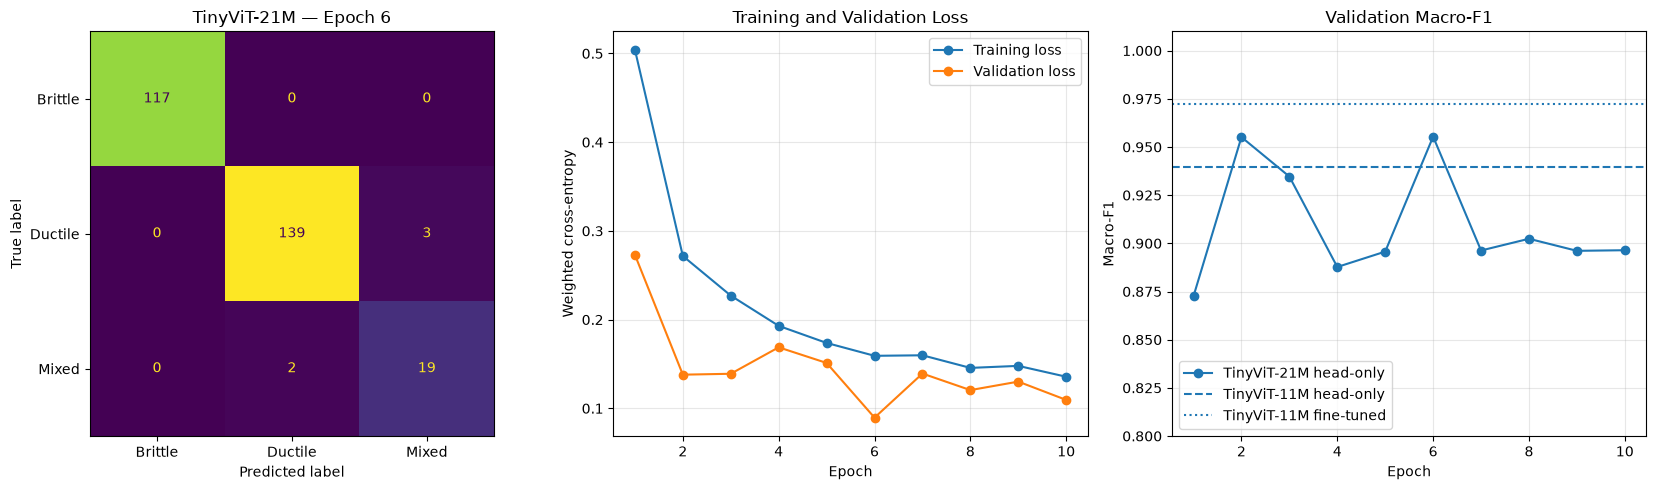


INCORRECT PREDICTIONS
------------------------------------------------------------
316L_AR_21_19.png | Actual: Ductile | Predicted: Mixed
316L_AR_21_20.png | Actual: Ductile | Predicted: Mixed
X65_AR_12_25.png | Actual: Ductile | Predicted: Mixed
316L_AR_04_15.png | Actual: Mixed | Predicted: Ductile
mX65_H2_26_29.png | Actual: Mixed | Predicted: Ductile

Total errors: 5
Correct predictions: 275

Diagnostic plot saved:
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m/plots/tinyvit_21m_head_only_diagnostics.png

Reserved test set remains untouched.


In [6]:

import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

# 1. Ensure best checkpoint is loaded
saved_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert saved_checkpoint["epoch"] == best_epoch

model.load_state_dict(
    saved_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# 2. Evaluate validation set
y_true = []
y_pred = []

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

# 3. Verify sample alignment
assert len(y_true) == 280

assert y_true == [
    class_to_idx[row["label"]]
    for row in val_records
]

# 4. Overall metrics
accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

assert abs(macro_f1 - best_f1) < 1e-5

print("TINYVIT-21M — BEST HEAD-ONLY CHECKPOINT")
print("=" * 60)

print("Best epoch:", best_epoch)
print(f"Validation accuracy: {accuracy:.4f}")
print(f"Validation macro-F1: {macro_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print("-" * 60)

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

# 5. Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

print("\nCONFUSION MATRIX")
print(cm)

# 6. Generate diagnostic plots
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
).plot(
    ax=axes[0],
    colorbar=False,
    values_format="d"
)

axes[0].set_title(
    f"TinyViT-21M — Epoch {best_epoch}"
)

epochs = range(
    1,
    len(history["train_loss"]) + 1
)

axes[1].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training loss"
)

axes[1].plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation loss"
)

axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Weighted cross-entropy")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(
    epochs,
    history["val_macro_f1"],
    marker="o",
    label="TinyViT-21M head-only"
)

axes[2].axhline(
    0.9396,
    linestyle="--",
    label="TinyViT-11M head-only"
)

axes[2].axhline(
    0.9721,
    linestyle=":",
    label="TinyViT-11M fine-tuned"
)

axes[2].set_title("Validation Macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")
axes[2].set_ylim(0.80, 1.01)
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()

plot_path = (
    PLOTS_DIR / "tinyvit_21m_head_only_diagnostics.png"
)

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 7. Identify classification errors
errors = []

for i, (actual, predicted) in enumerate(
    zip(y_true, y_pred)
):

    if actual != predicted:

        errors.append({
            "filename": val_records[i]["filename"],
            "actual": CLASSES[actual],
            "predicted": CLASSES[predicted]
        })

print("\nINCORRECT PREDICTIONS")
print("-" * 60)

for error in errors:

    print(
        f"{error['filename']} | "
        f"Actual: {error['actual']} | "
        f"Predicted: {error['predicted']}"
    )

print("\nTotal errors:", len(errors))
print("Correct predictions:", len(y_true) - len(errors))

print("\nDiagnostic plot saved:")
print(plot_path)

print("\nReserved test set remains untouched.")
